In [1]:
#Importing libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import ast
from datasets import load_dataset

#Loading the data
dataset = load_dataset('lukebarousse/data_jobs')
df = dataset['train'].to_pandas()

#Cleaning the date and skills columns
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else x)

c:\Users\amire\anaconda3\envs\python_course\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
# Defining countries that we will filter with
mena_countries = ['Sudan','Egypt', 'Kuwait', 'Saudi Arabia', 'Jordan', 'United Arab Emirates', 'Lebanon', 'Libya', 'Syria', 'Qatar', 'Iraq',
                   'Morocco', 'Palestine', 'Algeria', 'Tunisia', 'Bahrain', 'Oman', 'Yemen'  ]

# Defining job roles
job_roles = ['Data Analyst', 'Data Engineer', 'Data Scientist']

# Filtering data frame to have only the top three data roles in mena region countries
df_mena = df[(df['job_country'].isin(mena_countries)) & (df['job_title_short'].isin(job_roles)) ]

# Percentages of Data Analyst skills were not as expected, SQL was expected to score around 60%
# Potential cause: job_skills column for data analyst roles has NA values
da = df_mena[df_mena['job_title_short'] == 'Data Analyst']
print(len(da))                         
print(da['job_skills'].notna().sum())
# As the output reveals the job_skills column has 2326 NA values for data analyst role 
# Fix: Adding notna to initial filtering of the original df

df_mena = df[(df['job_country'].isin(mena_countries)) & (df['job_title_short'].isin(job_roles)) & (df['job_skills'].notna())]

df_mena['job_country'].unique()
# There are no job postings from Syria

7489
5163


<ArrowStringArray>
[               'Sudan', 'United Arab Emirates',              'Tunisia',
              'Lebanon',               'Kuwait',                'Egypt',
         'Saudi Arabia',              'Morocco',                 'Iraq',
               'Jordan',                'Qatar',                 'Oman',
              'Bahrain',                'Yemen',            'Palestine',
              'Algeria',                'Libya']
Length: 17, dtype: str

In [3]:
df_job_skills = df_mena.explode('job_skills')
df_job_skills_count = df_job_skills.groupby(['job_skills', 'job_title_short']).size()


In [4]:
df_job_skills_count = df_job_skills_count.reset_index(name= 'skill_count')


In [5]:
top_skills = df_job_skills_count.sort_values(by= ['job_title_short','skill_count'], ascending=[True,False]).groupby('job_title_short').head(5)

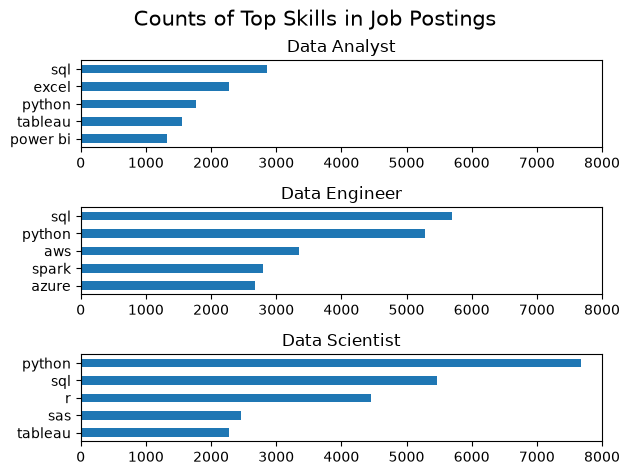

In [6]:
fig,ax = plt.subplots(3,1)
for i,roles in enumerate(job_roles):
    df_plot = top_skills[top_skills['job_title_short'] == roles]
    df_plot.plot(kind = 'barh', x= 'job_skills', y= 'skill_count', ax = ax[i], title = roles)
    ax[i].invert_yaxis()
    ax[i].set_ylabel('')
    ax[i].set_xlim(0,8000)
    ax[i].legend().set_visible(False)
fig.tight_layout(rect=[0, 0, 1, 0.95])


fig.suptitle('Counts of Top Skills in Job Postings', fontsize = 15)
plt.show()

In [7]:
# Adding percentage column to have a clearer picture of what's the likelihood of a role to appear in a job posting
df_job_title_count = df_mena['job_title_short'].value_counts().reset_index(name= 'jobs_total')
df_skill_perc = pd.merge(top_skills, df_job_title_count, how = 'left', on = 'job_title_short')

In [8]:
df_skill_perc['skill_percentage'] = df_skill_perc['skill_count'] / df_skill_perc['jobs_total'] * 100

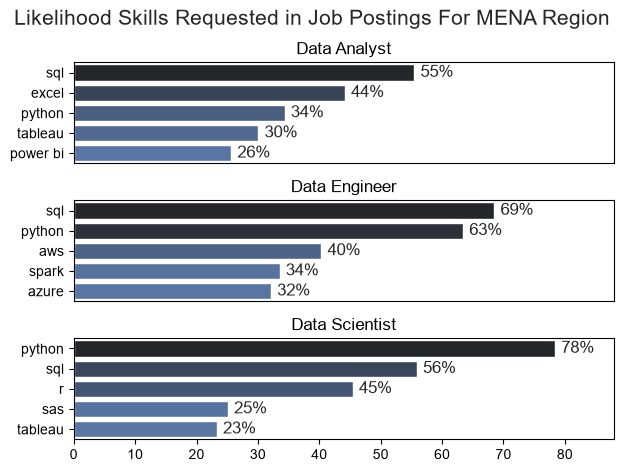

In [9]:
fig,ax = plt.subplots(3,1)

sns.set_theme(style = 'ticks')

for i,roles in enumerate(job_roles):
    df_plot = df_skill_perc[df_skill_perc['job_title_short'] == roles]
    sns.barplot(data = df_plot, y= 'job_skills', x= 'skill_percentage', ax = ax[i], hue = 'skill_count', palette = 'dark:b_r')

    ax[i].set_ylabel('')
    ax[i].set_xlabel('')
    ax[i].legend().set_visible(False)
    ax[i].set_title(roles)
    ax[i].set_xlim(0,88)

    for n,v in enumerate(df_plot['skill_percentage']):
        ax[i].text(v+1, n , f'{v:.0f}%', va= 'center')
        
    if i != 2 :
        ax[i].set_xticks([])

fig.tight_layout(h_pad=1, rect=[0, 0, 1, 0.95])
fig.suptitle('Likelihood Skills Requested in Job Postings For MENA Region', fontsize = 15)
plt.show()

In [10]:

df_mena

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_skills,job_type_skills
4,Data Engineer,Data Engineer- Sr Jobs,"Washington, DC",via Clearance Jobs,Full-time,False,Sudan,2023-08-07 14:29:36,False,False,Sudan,NaN,NaN,NaN,Kristina Daniel,"[bash, python, oracle, aws, ansible, puppet, j...","{'cloud': ['oracle', 'aws'], 'other': ['ansibl..."
62,Data Scientist,Data Scientist,"Austin, TX",via BeBee,Full-time,False,Sudan,2023-02-17 14:01:39,False,True,Sudan,NaN,NaN,NaN,ClosedLoop,"[python, go]","{'programming': ['python', 'go']}"
77,Data Engineer,Data Engineer,"Arlington, VA",via LinkedIn,Full-time,False,Sudan,2023-06-26 14:22:54,False,False,Sudan,year,140000.0,NaN,Intelletec,"[mongodb, mongodb, python, r, sql, mysql, mari...","{'analyst_tools': ['tableau'], 'cloud': ['orac..."
86,Data Engineer,Data Engineer,"Ridgefield Park, NJ",via SimplyHired,Full-time and Temp work,False,Sudan,2023-12-22 13:58:46,False,False,Sudan,NaN,NaN,NaN,Smartfox LLC,"[java, python, php, sql, shell, gcp, aws, spar...","{'cloud': ['gcp', 'aws'], 'libraries': ['spark..."
96,Data Engineer,Data Engineer,"Torrance, CA",via LinkedIn,Full-time,False,Sudan,2023-06-15 14:03:55,False,False,Sudan,NaN,NaN,NaN,King's Hawaiian,"[sql, r, python, sql server, azure, aws, spark...","{'analyst_tools': ['sap'], 'cloud': ['azure', ..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785482,Data Analyst,Database Analyst,"Doha, Qatar",via BeBee دولة قطر,Full-time,False,Qatar,2023-12-05 06:37:19,True,False,Qatar,NaN,NaN,NaN,Kidzania Doha,"[sql, sql server, mysql, azure, windows, ssrs,...","{'analyst_tools': ['ssrs', 'power bi', 'ssis']..."
785557,Data Scientist,"Data Scientist, All Levels",United States,via Trabajo.org,Full-time,False,Sudan,2023-10-13 07:15:15,False,True,Sudan,NaN,NaN,NaN,Independent Software,"[python, c, shell, bash, perl]","{'programming': ['python', 'c', 'shell', 'bash..."
785633,Data Analyst,Data Analyst Senior - Full-time / Part-time,"Albuquerque, NM",via Snagajob,Full-time,False,Sudan,2023-01-22 07:22:17,False,False,Sudan,NaN,NaN,NaN,"Bernalillo County, NM",[terminal],{'other': ['terminal']}
785731,Data Engineer,Data Engineer,"Overland Park, Kansas, Amerika Serikat",melalui LinkedIn,Pekerjaan tetap,False,Sudan,2023-03-12 06:32:17,False,False,Sudan,NaN,NaN,NaN,Shamrock Trading Corporation,"[nosql, mongodb, mongodb, python, elasticsearc...","{'analyst_tools': ['excel'], 'cloud': ['aws', ..."
